In [1]:
##https://www.youtube.com/watch?v=rTEtEy5o3X0
## outstanding video

In [2]:
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
cmap = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

iris = datasets.load_iris()

X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)


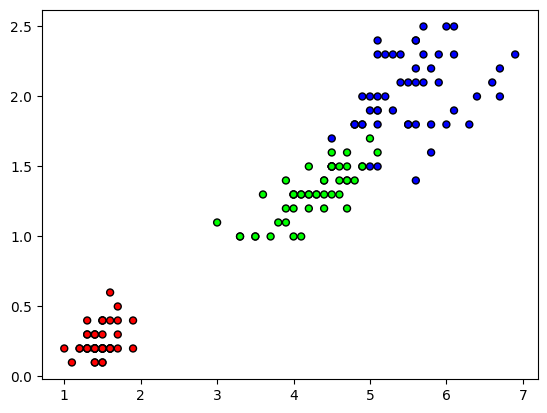

In [3]:
#iris
plt.figure()
plt.scatter(X[:,2], X[:, 3], c=y, cmap=cmap, edgecolor='k', s=25)
plt.show() #before training

In [4]:
#classifier passing our class from same file or other file
clf = KNN()
clf.fit(X_train, y_train)
predictions = clf.predict(X_test)
print(predictions)

NameError: name 'KNN' is not defined

In [ ]:
#calculate accuracy_

acc = np.sum(predictions == y_test) / len(y_test)
print(acc)

1.0


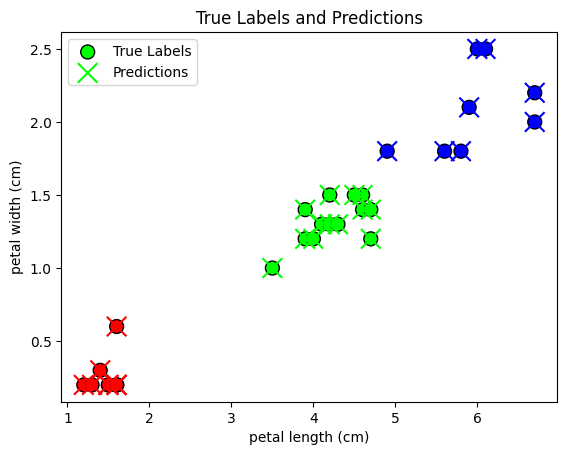

In [ ]:
#plot predictions
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])
plt.figure()
# Plot the test points with true labels
plt.scatter(X_test[:, 2], X_test[:, 3], c=y_test, cmap=cmap_bold, edgecolor='k', s=100, label='True Labels')

# Overlay predicted labels
plt.scatter(X_test[:, 2], X_test[:, 3], c=predictions, marker='x', cmap=cmap_bold, s=200, label='Predictions')

plt.xlabel(iris.feature_names[2])
plt.ylabel(iris.feature_names[3])
plt.legend()
plt.title("True Labels and Predictions")
plt.show()

# KNN model

In [ ]:

import numpy as np
from collections import Counter

def euclidean_distance(x1,x2):
  distance= np.sqrt(np.sum((x1-x2)**2))
  return distance
#

class KNN:
  def __init__(self, k=3):
    self.k = k

  #keeps the values for x and y datasets
  def fit(self, X, Y):
    self.X_train = X
    self.y_train = Y

  #here we make calculations of distance. We pass X, the dataset we wat to make predictions for
  def predict(self, X):
    pred = [self._predict(x) for x in X] #for each of the samples (x) in the dataset X
    return pred

  #Calculates the distance of that x from all the points in X and return the label based on the 3 (k=3 or more) nearest neighbours
  def _predict(self, x):
    #compute distance (euclidian)
    distances = [euclidean_distance(x, x_train) for x_train in self.X_train]

    #get closest k
    k_indices = np.argsort(distances)[:self.k]
    k_nearest_labels = [self.y_train[i] for i in k_indices]
                             #argsort tells you where the original indices from the original array are after sorting

    #majority
    most_common = Counter(k_nearest_labels).most_common()
    return most_common[0][0] #only names of labels
